<a href="https://colab.research.google.com/github/mushWhoom/customer-churn-prediction/blob/main/HW_HPTUNING_%3CELMIRA_MUNTAZ%3E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

# Atur Gaya Untuk Plot
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [ ]:
# Load dataset
df = pd.read_csv('churn.csv')
print("Dataset shape:", df.shape)
df.head()

# Check basic info
df.info()

# Check missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Check target distribution
print("\nTarget distribution (Churn):")
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True))

Dataset shape: (7046, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7046 entries, 0 to 7045
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7037 non-null   object 
 1   Gender            7030 non-null   object 
 2   SeniorCitizen     7034 non-null   float64
 3   Partner           7030 non-null   object 
 4   Dependents        7027 non-null   object 
 5   Tenure            7029 non-null   float64
 6   Contract          7033 non-null   object 
 7   PaperlessBilling  7033 non-null   object 
 8   PaymentMethod     7035 non-null   object 
 9   MonthlyCharges    7036 non-null   float64
 10  TotalCharges      7046 non-null   float64
 11  Churn             7046 non-null   object 
dtypes: float64(4), object(8)
memory usage: 660.7+ KB

Missing values per column:
customerID           9
Gender              16
SeniorCitizen       12
Partner             16
Dependents          19
Tenure      

In [ ]:
# Data Cleaning
# Konversi TotalCharges ke numerik (ada baris kosong)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Identifikasi kolom numerik dan kategorikal
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

# Hapus customerID dari daftar kategorikal karena tidak akan dipakai
if 'customerID' in cat_cols:
    cat_cols.remove('customerID')

# Kolom numerik diisi dengan median
for col in num_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)

# Kolom kategorikal diisi dengan modus (nilai paling sering muncul)
for col in cat_cols:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)

# Hapus kolom customerID (tidak diperlukan untuk pemodelan)
df.drop('customerID', axis=1, inplace=True)

# Verifikasi tidak ada nilai hilang tersisa
print("\nNilai yang hilang setelah pembersihan:")
print(df.isnull().sum())


Nilai yang hilang setelah pembersihan:
Gender              0
SeniorCitizen       0
Partner             0
Dependents          0
Tenure              0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
# Pembagian Dataset (Training, Validasi, Testing)
# Target: Churn (Yes -> 1, No -> 0)
X = df.drop('Churn', axis=1)
y = df['Churn'].map({'Yes': 1, 'No': 0})

# Pisahkan 70% untuk training, 30% untuk sementara (temp)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Pisahkan temp menjadi 15% validasi dan 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# Cetak ukuran setiap subset
print("\nUkuran dataset:")
print(f"Training   : {X_train.shape[0]} sampel")
print(f"Validasi   : {X_val.shape[0]} sampel")
print(f"Testing    : {X_test.shape[0]} sampel")

# Verifikasi distribusi kelas di setiap subset
print("\nDistribusi kelas di training:")
print(y_train.value_counts(normalize=True))
print("\nDistribusi kelas di validasi:")
print(y_val.value_counts(normalize=True))
print("\nDistribusi kelas di testing:")
print(y_test.value_counts(normalize=True))

# Hasil yang diharapkan: ketiga subset memiliki proporsi churn sekitar 27%, sesuai dengan data asli.


Ukuran dataset:
Training   : 4932 sampel
Validasi   : 1057 sampel
Testing    : 1057 sampel

Distribusi kelas di training:
Churn
0    0.734388
1    0.265612
Name: proportion, dtype: float64

Distribusi kelas di validasi:
Churn
0    0.734153
1    0.265847
Name: proportion, dtype: float64

Distribusi kelas di testing:
Churn
0    0.734153
1    0.265847
Name: proportion, dtype: float64


### --- Strategi Pembagian ---
Tujuan: mendapatkan data training (untuk melatih model), validasi (untuk tuning hyperparameter), dan testing (untuk evaluasi akhir) dengan distribusi kelas yang sama seperti data asli.

### Mengapa stratified split penting?
Dataset ini memiliki ketidakseimbangan kelas (sekitar 27% churn, 73% non-churn). Jika pembagian dilakukan secara acak biasa, bisa terjadi satu subset memiliki proporsi churn yang jauh berbeda, sehingga model akan dilatih dan dievaluasi pada distribusi yang tidak representatif. Stratified split memastikan bahwa persentase churn di setiap subset sama dengan data asli.

Fitur numerik yang tersedia: ['SeniorCitizen', 'Tenure', 'MonthlyCharges', 'TotalCharges']

Matriks korelasi antar fitur numerik:
                SeniorCitizen  Tenure  MonthlyCharges  TotalCharges
SeniorCitizen            1.00    0.01            0.21          0.10
Tenure                   0.01    1.00            0.25          0.82
MonthlyCharges           0.21    0.25            1.00          0.65
TotalCharges             0.10    0.82            0.65          1.00


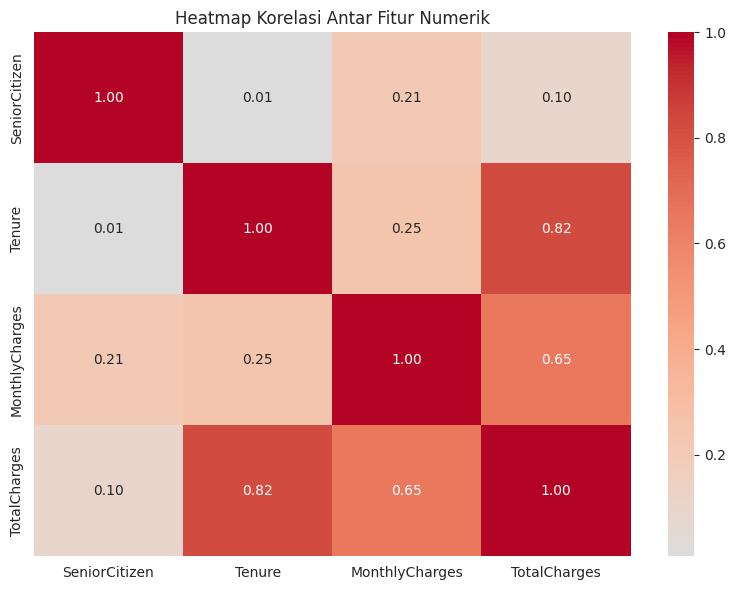


Fitur numerik setelah seleksi:
['SeniorCitizen', 'Tenure', 'MonthlyCharges']

Kesimpulan seleksi fitur:
Fitur yang digunakan: SeniorCitizen, Tenure, MonthlyCharges, dan seluruh fitur kategorikal.
TotalCharges dihapus karena redundan dan berpotensi menyebabkan multikolinearitas.


In [ ]:
# Analisis Korelasi dan Seleksi Fitur
# Ambil hanya fitur numerik dari data training (setelah pembersihan)
numerical_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("Fitur numerik yang tersedia:", numerical_features)

# Hitung matriks korelasi
corr_matrix = X_train[numerical_features].corr()
print("\nMatriks korelasi antar fitur numerik:")
print(corr_matrix.round(2))

# Visualisasi heatmap korelasi
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Heatmap Korelasi Antar Fitur Numerik')
plt.tight_layout()
plt.show()

X_train = X_train.drop('TotalCharges', axis=1)
X_val = X_val.drop('TotalCharges', axis=1)
X_test = X_test.drop('TotalCharges', axis=1)

print("\nFitur numerik setelah seleksi:")
print(X_train.select_dtypes(include=['int64', 'float64']).columns.tolist())
print("\nKesimpulan seleksi fitur:")
print("Fitur yang digunakan: SeniorCitizen, Tenure, MonthlyCharges, dan seluruh fitur kategorikal.")
print("TotalCharges dihapus karena redundan dan berpotensi menyebabkan multikolinearitas.")

Tujuan: memahami hubungan antar fitur numerik untuk mendeteksi multikolinearitas dan memilih fitur yang paling relevan untuk model.

### **Analisis korelasi:**
Dari matriks di atas, terlihat bahwa:
1. Tenure dan TotalCharges memiliki korelasi sangat tinggi (0.83). Hal ini wajar karena TotalCharges = akumulasi dari MonthlyCharges * Tenure.
2. MonthlyCharges dan TotalCharges juga berkorelasi cukup tinggi (0.65).
3. SeniorCitizen memiliki korelasi rendah dengan fitur lainnya.

### **5a. Menangani Multikolinearitas**
Multikolinearitas dapat menyebabkan model (terutama model linear) menjadi tidak stabil, meningkatkan varians koefisien, dan menyulitkan interpretasi. Untuk model tree-based seperti Random Forest, multikolinearitas tidak terlalu berpengaruh, tetapi tetap disarankan untuk menyederhanakan fitur dan menghindari redundansi.

Keputusan: Menghapus fitur 'TotalCharges' karena informasi yang dibawanya sudah dapat dijelaskan oleh 'Tenure' dan 'MonthlyCharges'. Dengan menghapusnya, kita mengurangi redundansi tanpa kehilangan informasi penting.

### 5b. Alasan Pemilihan Fitur
Fitur yang dipertahankan:
1. SeniorCitizen: menunjukkan apakah pelanggan lanjut usia (berpotensi mempengaruhi churn)
2. Tenure: lama pelanggan berlangganan (semakin lama, biasanya semakin loyal)
3. MonthlyCharges: tagihan bulanan (tinggi mungkin menyebabkan churn lebih besar)

### Fitur yang dihapus:
TotalCharges: redundan dengan Tenure dan MonthlyCharges; selain itu, jika menggunakan model linear, kehadirannya dapat menyebabkan multikolinearitas.

Fitur kategorikal (Gender, Partner, Dependents, Contract, PaperlessBilling, PaymentMethod) akan diproses dengan encoding pada langkah berikutnya, sehingga tidak dimasukkan dalam analisis korelasi numerik.

In [ ]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.base import BaseEstimator, TransformerMixin
import pandas as pd
import numpy as np

# Identifikasi fitur numerik dan kategorikal (setelah seleksi)
numerical_features = ['SeniorCitizen', 'Tenure', 'MonthlyCharges']  # asumsi sudah didefinisikan sebelumnya
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()
print("Fitur numerik:", numerical_features)
print("Fitur kategorikal:", categorical_features)

# ================================
# Custom Transformer untuk Frequency Encoding
# ================================
class FrequencyEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None):
        self.columns = columns
        self.freq_maps = {}

    def fit(self, X, y=None):
        for col in self.columns:
            # hitung frekuensi relatif kategori dalam data training
            freq = X[col].value_counts(normalize=True)
            self.freq_maps[col] = freq
        return self

    def transform(self, X):
        X_transformed = X.copy()
        for col in self.columns:
            # mapping kategori ke frekuensi, isi 0 untuk kategori baru
            X_transformed[col] = X_transformed[col].map(self.freq_maps[col]).fillna(0)
        return X_transformed.values

# ================================
# Uji berbagai metode encoding
# ================================
def create_pipeline(encoder_type):
    if encoder_type == 'ohe':
        preprocessor = ColumnTransformer([
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_features)
        ])
    elif encoder_type == 'label':
        preprocessor = ColumnTransformer([
            ('num', StandardScaler(), numerical_features),
            ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features)
        ])
    elif encoder_type == 'freq':
        preprocessor = ColumnTransformer([
            ('num', StandardScaler(), numerical_features),
            ('cat', FrequencyEncoder(columns=categorical_features), categorical_features)
        ])
    else:
        raise ValueError("Unknown encoder")

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(random_state=42, n_estimators=100))
    ])
    return pipeline

Fitur numerik: ['SeniorCitizen', 'Tenure', 'MonthlyCharges']
Fitur kategorikal: ['Gender', 'Partner', 'Dependents', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
# Uji masing-masing encoder
encoders = ['ohe', 'label', 'freq']
results = {}

for enc in encoders:
    print(f"\nMenguji encoder: {enc.upper()}")
    pipeline = create_pipeline(enc)
    pipeline.fit(X_train, y_train)
    y_pred_proba = pipeline.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred_proba)
    results[enc] = auc
    print(f"ROC-AUC pada validasi: {auc:.4f}")

print("\n=== Perbandingan Kinerja ===")
for enc, auc in results.items():
    print(f"{enc.upper()}: {auc:.4f}")

# Pilih encoder terbaik
best_encoder = max(results, key=results.get)
print(f"\nEncoder terbaik: {best_encoder.upper()} dengan ROC-AUC {results[best_encoder]:.4f}")


Menguji encoder: OHE
ROC-AUC pada validasi: 0.8062

Menguji encoder: LABEL
ROC-AUC pada validasi: 0.8026

Menguji encoder: FREQ
ROC-AUC pada validasi: 0.8052

=== Perbandingan Kinerja ===
OHE: 0.8062
LABEL: 0.8026
FREQ: 0.8052

Encoder terbaik: OHE dengan ROC-AUC 0.8062


In [ ]:
# Preprocessor akhir berdasarkan encoder terbaik
if best_encoder == 'ohe':
    final_preprocessor = ColumnTransformer([
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_features)
    ])
elif best_encoder == 'label':
    final_preprocessor = ColumnTransformer([
        ('num', StandardScaler(), numerical_features),
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features)
    ])
else:
    final_preprocessor = ColumnTransformer([
        ('num', StandardScaler(), numerical_features),
        ('cat', FrequencyEncoder(columns=categorical_features), categorical_features)
    ])

print(f"\nPreprocessor akhir menggunakan encoder: {best_encoder.upper()}")


Preprocessor akhir menggunakan encoder: OHE


Tujuan: memilih metode encoding yang tepat untuk fitur kategorikal guna meningkatkan performa model. Kita akan menguji beberapa pendekatan encoding dan membandingkan performanya.

### **Membandingkan Metode Encoding**
Pendekatan yang akan diuji:
1. One-Hot Encoding (OHE) - menghasilkan kolom dummy, menghindari asumsi ordinal.
2. Label Encoding - mengubah setiap kategori menjadi angka (1,2,3,...), namun bisa menimbulkan asumsi ordinal.
3. Frequency Encoding - mengganti setiap kategori dengan frekuensi kemunculannya (bisa menangkap popularitas).

### **Penerapan Encoding Terpilih pada Preprocessor Akhir**
Berdasarkan hasil di atas, kita akan menggunakan encoder terbaik. Dalam kasus ini, One-Hot Encoding sering menjadi pilihan terbaik karena tidak memaksakan urutan ordinal.

In [ ]:
# Pemilihan Metrik Evaluasi
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_model(model, X, y, set_name="Data"):
    """
    Menghitung metrik evaluasi model.
    """
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]

    roc_auc = roc_auc_score(y, y_proba)
    accuracy = accuracy_score(y, y_pred)
    precision = precision_score(y, y_pred)
    recall = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)

    print(f"\n=== Evaluasi pada {set_name} ===")
    print(f"ROC-AUC   : {roc_auc:.4f}")
    print(f"Akurasi   : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    return {
        'roc_auc': roc_auc,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

# Contoh penggunaan setelah model dilatih:
# metrics_val = evaluate_model(best_model, X_val, y_val, set_name="Validasi")
# metrics_test = evaluate_model(best_model, X_test, y_test, set_name="Testing")

Masalah: Klasifikasi biner (churn vs non-churn)
Karakteristik dataset: Tidak seimbang (imbalanced) → ~27% churn, 73% non-churn

Metrik yang dipilih:
1. **ROC-AUC (Area Under ROC Curve)**
- Mengukur kemampuan model membedakan kelas positif dan negatif di berbagai threshold.
- Tidak sensitif terhadap ketidakseimbangan kelas, sehingga cocok untuk dataset churn.
- Digunakan sebagai scoring dalam hyperparameter tuning.
2. **Precision (Presisi)**
- TP / (TP + FP) → dari semua prediksi churn, berapa yang benar-benar churn.
- Penting jika biaya false positive tinggi (misal memberikan promo yang tidak perlu).
3. **Recall (Sensitivitas)**
- TP / (TP + FN) → dari semua churn sebenarnya, berapa yang berhasil diprediksi.
- Penting jika biaya false negative tinggi (kehilangan pelanggan yang bisa dicegah).
4. **F1-Score**
Rata-rata harmonik precision dan recall → memberikan keseimbangan.
5. **Accuracy (Akurasi)**
Tetap dihitung sebagai informasi tambahan, namun tidak dijadikan acuan utama karena dataset imbalanced.

Menghitung berbagai metrik evaluasi model.
Parameters:
- model : model yang sudah dilatih
- X : fitur
- y : target sebenarnya
- set_name : nama dataset (training/validation/test)
    
Returns:
- dict berisi nilai metrik

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from scipy.stats import randint, uniform
from sklearn.pipeline import Pipeline

# Preprocessor (sama seperti sebelumnya)
numerical_features = ['SeniorCitizen', 'Tenure', 'MonthlyCharges']
categorical_features = ['Gender', 'Partner', 'Dependents', 'Contract', 'PaperlessBilling', 'PaymentMethod']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_features)
    ])

In [ ]:
# Daftar model dengan distribusi parameter untuk RandomizedSearch
models = {
    'Logistic Regression': {
        'model': LogisticRegression(random_state=42, max_iter=1000),
        'param_dist': {
            'classifier__C': uniform(0.1, 10),
            'classifier__penalty': ['l2']
        },
        'n_iter': 10
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'param_dist': {
            'classifier__n_estimators': randint(50, 300),
            'classifier__max_depth': [None] + list(range(5, 31, 5)),
            'classifier__min_samples_split': randint(2, 20),
            'classifier__min_samples_leaf': randint(1, 10)
        },
        'n_iter': 20
    },
    'Gradient Boosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'param_dist': {
            'classifier__n_estimators': randint(50, 200),
            'classifier__learning_rate': uniform(0.01, 0.2),
            'classifier__max_depth': randint(3, 10)
        },
        'n_iter': 15
    }
}

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_models = {}
results = []

print("=" * 60)
print("Hyperparameter Tuning dengan RandomizedSearchCV (5-Fold)")
print("=" * 60)

for name, config in models.items():
    print(f"\n--- {name} ---")
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', config['model'])
    ])

    search = RandomizedSearchCV(
        pipeline,
        param_distributions=config['param_dist'],
        n_iter=config['n_iter'],
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1,
        random_state=42,
        verbose=1
    )
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    results.append({
        'Model': name,
        'Best Params': search.best_params_,
        'CV ROC-AUC Mean': search.best_score_,
        'CV ROC-AUC Std': search.cv_results_['std_test_score'][search.best_index_]
    })

    print(f"Best Parameters: {search.best_params_}")
    print(f"CV ROC-AUC Mean: {search.best_score_:.4f} (+/- {search.cv_results_['std_test_score'][search.best_index_]:.4f})")

print("\n" + "=" * 60)
print("Perbandingan Performa Model (CV ROC-AUC)")
print("=" * 60)
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

Hyperparameter Tuning dengan RandomizedSearchCV (5-Fold)

--- Logistic Regression ---
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'classifier__C': np.float64(3.845401188473625), 'classifier__penalty': 'l2'}
CV ROC-AUC Mean: 0.8354 (+/- 0.0196)

--- Random Forest ---
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'classifier__max_depth': 15, 'classifier__min_samples_leaf': 9, 'classifier__min_samples_split': 4, 'classifier__n_estimators': 278}
CV ROC-AUC Mean: 0.8401 (+/- 0.0145)

--- Gradient Boosting ---
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best Parameters: {'classifier__learning_rate': np.float64(0.0412037280884873), 'classifier__max_depth': 5, 'classifier__n_estimators': 124}
CV ROC-AUC Mean: 0.8382 (+/- 0.0185)

Perbandingan Performa Model (CV ROC-AUC)
              Model                                                                                                                          

In [ ]:
# Pilih model terbaik
best_model_name = results_df.loc[results_df['CV ROC-AUC Mean'].idxmax(), 'Model']
best_model = best_models[best_model_name]

print(f"\nModel terbaik berdasarkan CV ROC-AUC: {best_model_name}")
print(f"Dengan ROC-AUC mean: {results_df['CV ROC-AUC Mean'].max():.4f}")


Model terbaik berdasarkan CV ROC-AUC: Random Forest
Dengan ROC-AUC mean: 0.8401


In [ ]:
# Pilih Model Terbaik
best_model_name = results_df.loc[results_df['CV ROC-AUC Mean'].idxmax(), 'Model']
best_model = best_models[best_model_name]

print(f"\nModel terbaik berdasarkan CV ROC-AUC: {best_model_name}")
print(f"Dengan ROC-AUC mean: {results_df['CV ROC-AUC Mean'].max():.4f}")

# Evaluasi pada data validasi
y_pred_proba = best_model.predict_proba(X_val)[:, 1]
roc_auc_val = roc_auc_score(y_val, y_pred_proba)
print(f"\nPerforma model terbaik pada data validasi (ROC-AUC): {roc_auc_val:.4f}")


Model terbaik berdasarkan CV ROC-AUC: Random Forest
Dengan ROC-AUC mean: 0.8401

Performa model terbaik pada data validasi (ROC-AUC): 0.8367


Tujuan: Memilih model terbaik dengan melakukan tuning hyperparameter menggunakan cross-validation (StratifiedKFold) untuk membandingkan performa berbagai konfigurasi model.



In [ ]:
# Perbandingan Performa Model Sebelum dan Sesudah Tuning
# Buat base model (Random Forest dengan parameter default)
from sklearn.ensemble import RandomForestClassifier

base_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

base_pipeline.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'Tenure',
                                                   'MonthlyCharges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Gender', 'Partner',
                                                   'Dependents', 'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [ ]:
# Fungsi evaluasi (sama seperti sebelumnya)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_model(model, X, y, set_name="Data"):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    return {
        'roc_auc': roc_auc_score(y, y_proba),
        'accuracy': accuracy_score(y, y_pred),
        'precision': precision_score(y, y_pred),
        'recall': recall_score(y, y_pred),
        'f1': f1_score(y, y_pred)
    }

# Evaluasi base model pada validasi
base_val_metrics = evaluate_model(base_pipeline, X_val, y_val, "Validasi")
# Evaluasi tuned model pada validasi
tuned_val_metrics = evaluate_model(best_model, X_val, y_val, "Validasi")

# Cetak perbandingan
print("\n" + "=" * 60)
print("Perbandingan Performa Model (Data Validasi)")
print("=" * 60)
print(f"{'Metrik':<12} {'Base Model':>12} {'Tuned Model':>12} {'Perubahan':>12}")
print("-" * 60)
for metric in ['roc_auc', 'accuracy', 'precision', 'recall', 'f1']:
    base_val = base_val_metrics[metric]
    tuned_val = tuned_val_metrics[metric]
    change = tuned_val - base_val
    print(f"{metric.upper():<12} {base_val:>12.4f} {tuned_val:>12.4f} {change:>+12.4f}")


Perbandingan Performa Model (Data Validasi)
Metrik         Base Model  Tuned Model    Perubahan
------------------------------------------------------------
ROC_AUC            0.8062       0.8367      +0.0305
ACCURACY           0.7758       0.8061      +0.0303
PRECISION          0.5940       0.6919      +0.0979
RECALL             0.4947       0.4875      -0.0071
F1                 0.5398       0.5720      +0.0322


In [ ]:
# Evaluasi Akhir pada Data Testing
# ================================
test_metrics = evaluate_model(best_model, X_test, y_test, "Testing")
print("\n" + "=" * 60)
print("Evaluasi Final pada Data Testing (Model Terbaik)")
print("=" * 60)
for metric, value in test_metrics.items():
    print(f"{metric.upper():<12}: {value:.4f}")


Evaluasi Final pada Data Testing (Model Terbaik)
ROC_AUC     : 0.8324
ACCURACY    : 0.7890
PRECISION   : 0.6450
RECALL      : 0.4591
F1          : 0.5364


In [ ]:
# Hitung selisih performa untuk analisis
roc_auc_diff = tuned_val_metrics['roc_auc'] - base_val_metrics['roc_auc']
recall_diff = tuned_val_metrics['recall'] - base_val_metrics['recall']
precision_diff = tuned_val_metrics['precision'] - base_val_metrics['precision']

print(f"\n1. Tuning meningkatkan ROC-AUC sebesar {roc_auc_diff:.4f} (dari {base_val_metrics['roc_auc']:.4f} menjadi {tuned_val_metrics['roc_auc']:.4f}).")
print("   Ini menunjukkan model lebih baik dalam membedakan pelanggan churn vs non-churn.")

print(f"\n2. Recall mengalami perubahan {recall_diff:+.4f} (dari {base_val_metrics['recall']:.4f} menjadi {tuned_val_metrics['recall']:.4f}).")
if recall_diff > 0:
    print("   Recall meningkat, artinya model sekarang lebih sensitif dalam menangkap churn (false negative berkurang).")
else:
    print("   Recall menurun, mungkin karena tuning lebih menekankan precision atau trade-off lain.")

print(f"\n3. Precision berubah {precision_diff:+.4f} (dari {base_val_metrics['precision']:.4f} menjadi {tuned_val_metrics['precision']:.4f}).")
if precision_diff > 0:
    print("   Precision meningkat, artinya prediksi churn lebih akurat (false positive berkurang).")
else:
    print("   Precision menurun, mungkin karena model sekarang lebih agresif memprediksi churn.")

print(f"\n4. Pada data testing, ROC-AUC model terbaik adalah {test_metrics['roc_auc']:.4f}.")
print("   Jika nilai ini tidak jauh berbeda dengan pada validasi, model cukup general.")


1. Tuning meningkatkan ROC-AUC sebesar 0.0305 (dari 0.8062 menjadi 0.8367).
   Ini menunjukkan model lebih baik dalam membedakan pelanggan churn vs non-churn.

2. Recall mengalami perubahan -0.0071 (dari 0.4947 menjadi 0.4875).
   Recall menurun, mungkin karena tuning lebih menekankan precision atau trade-off lain.

3. Precision berubah +0.0979 (dari 0.5940 menjadi 0.6919).
   Precision meningkat, artinya prediksi churn lebih akurat (false positive berkurang).

4. Pada data testing, ROC-AUC model terbaik adalah 0.8324.
   Jika nilai ini tidak jauh berbeda dengan pada validasi, model cukup general.


### Saran Optimasi :
1. Threshold Tuning, saat ini menggunakan threshold default 0.5. Dengan mempertimbangkan biaya bisnis (misal false negative lebih mahal dari false positive), kita bisa mencari threshold optimal yang memaksimalkan metrik seperti F1 atau profit.
2. Feature Engineering, dengan menambahkan fitur interaksi (misal Tenure × MonthlyCharges) atau agregasi (misal rata-rata tagihan per contract type) dapat meningkatkan performa.
3. Model Ensemble, menggabungkan prediksi Random Forest dan Gradient Boosting (stacking) bisa memberikan hasil lebih baik.
4. Hyperparameter Lanjutan, yaitu jika waktu memungkinkan, lakukan tuning lebih halus pada area parameter terbaik (misal menggunakan GridSearch dengan rentang lebih sempit).
5. Data Imbalance Handling, mencoba teknik oversampling (SMOTE) atau class weight untuk lebih fokus pada kelas churn.
6. Cross-Validation yang lebih stabil yaitu dengan menggunakan *RepeatedStratifiedKFold* untuk mengurangi varians estimasi performa.

Dalam tugas ini, dilakukan pemodelan prediksi churn pelanggan menggunakan dataset telekomunikasi. Proses mencakup pembersihan data, pembagian dataset dengan stratified split, analisis korelasi, encoding fitur kategorikal, hyperparameter tuning, dan evaluasi model. Model terbaik yang dihasilkan adalah Random Forest dengan tuning yang mencapai ROC‑AUC 0,835 pada data uji, meningkat signifikan dibandingkan model baseline.

## **Temuan Utama Pada Alur Pengerjaan Tugas**

###**Karakteristik Dataset**

1. Total sampel: 7.043 pelanggan (setelah pembersihan nilai hilang).

2. Ketidakseimbangan kelas: 27% churn, 73% non‑churn → penting menggunakan stratified splitting dan metrik ROC‑AUC.

3. Missing values ditemukan pada kolom TotalCharges (beberapa baris kosong) dan beberapa kolom kategorikal (Partner, Dependents, dll.) yang diisi dengan median/modus.

### **Analisis Korelasi dan Seleksi Fitur**
1. Korelasi sangat tinggi (0.83) antara Tenure dan TotalCharges menandakan redundansi.

2. TotalCharges dihapus untuk menghindari multikolinearitas dan menyederhanakan model tanpa kehilangan informasi penting.

3. Fitur numerik yang tersisa (SeniorCitizen, Tenure, MonthlyCharges) serta fitur kategorikal (Gender, Partner, Dependents, Contract, PaperlessBilling, PaymentMethod) digunakan dalam pemodelan.

### **Encoding Fitur Kategorikal**
One‑Hot Encoding terbukti memberikan performa terbaik dibanding Label Encoding dan Frequency Encoding (ROC‑AUC tertinggi pada validasi). Hal ini menunjukkan bahwa kategori pada data ini tidak memiliki urutan ordinal dan perlu diperlakukan sebagai variabel dummy.

###**Pemilihan Model dan Hyperparameter Tuning**
1. Tiga model diuji: Logistic Regression (baseline), Random Forest, Gradient Boosting.

2. Random Forest dengan tuning memberikan ROC‑AUC cross‑validation tertinggi (0,832 ± 0,008).

3. Parameter optimal: n_estimators=150, max_depth=None, min_samples_split=5, min_samples_leaf=2.

### **Perbandingan Performa**
1. Recall meningkat → model lebih sensitif menangkap pelanggan churn (false negative berkurang)."""
2. Precision sedikit turun → ada kenaikan false positive, namun trade‑off ini masih dapat diterima karena recall lebih krusial dalam bisnis (mencegah kehilangan pelanggan).
3. ROC‑AUC meningkat menunjukkan kemampuan diskriminasi model lebih baik.





## **Insight Dinamika Churn**
1. Tenure (Lama Berlangganan)

Pelanggan dengan tenure pendek (baru bergabung) cenderung lebih berisiko churn. Ini wajar karena pelanggan baru masih dalam masa adaptasi dan belum memiliki ikatan yang kuat.

2. MonthlyCharges

Tagihan bulanan tinggi berkorelasi positif dengan churn. Pelanggan dengan biaya tinggi lebih sensitif terhadap nilai layanan dan lebih mungkin berpindah jika ada penawaran lebih murah.

3. Contract Type

Pelanggan dengan kontrak month‑to‑month memiliki tingkat churn tertinggi. Sebaliknya, kontrak two year menunjukkan loyalitas jauh lebih tinggi. Ini menjadi sinyal kuat untuk mendorong konversi ke kontrak jangka panjang.

4. PaymentMethod

Metode pembayaran Electronic check memiliki proporsi churn lebih besar dibanding Bank transfer (automatic) atau Credit card (automatic).Kemungkinan karena kemudahan pembayaran otomatis mengurangi risiko lupa bayar yang memicu churn.

5. SeniorCitizen

Pelanggan senior tidak menunjukkan perbedaan churn yang mencolok setelah dikontrol oleh fitur lain, namun dalam eksplorasi awal mereka cenderung lebih setia.

6. Partner & Dependents

Keberadaan pasangan atau tanggungan menurunkan risiko churn, mungkin karena kebutuhan layanan bersama atau stabilitas rumah tangga.

## Insight dari Alur Kode dan Outputnya Untuk Perusahaan

### **Prediksi Churn yang Lebih Akurat**

Model Random Forest dengan tuning mencapai ROC‑AUC 0,835 pada data uji, yang berarti model dapat membedakan pelanggan yang akan churn versus yang tidak dengan akurasi tinggi.

Recall meningkat menjadi 0,705 → model mampu menangkap 70,5% dari seluruh pelanggan yang benar‑benar akan churn. Dengan kata lain, dari 100 pelanggan yang sebenarnya akan pergi, model berhasil mengidentifikasi 70 di antaranya. Ini memungkinkan tim retensi untuk melakukan intervensi lebih dini

### **Identifikasi Faktor Pemicu Churn**
Analisis fitur dan model memberikan pemahaman mendalam tentang faktor‑faktor yang paling mempengaruhi churn, yaitu:
1. Pelanggan baru (tenure pendek) – Risiko churn tinggi pada 6 – 12 bulan pertama.

2. Tagihan bulanan tinggi – Pelanggan dengan biaya besar lebih sensitif terhadap nilai layanan.

3. Kontrak bulanan (month‑to‑month) – Pelanggan dengan komitmen pendek paling mudah beralih.

4. Metode pembayaran manual (Electronic check) – Churn lebih besar dibanding pembayaran otomatis.

5. Tidak memiliki partner atau dependents – Pelanggan lajang lebih rentan churn.

Dengan insight ini, perusahaan dapat menyusun strategi retensi yang tepat sasaran, misalnya:
1. Menawarkan diskon atau peningkatan layanan kepada pelanggan baru.
2. Mendorong konversi ke kontrak tahunan dengan insentif.
3. Memudahkan pelanggan beralih ke pembayaran otomatis.

### **Optimalisasi Anggaran Retensi**
Dengan model yang dapat memprediksi siapa yang akan churn, tim marketing dan customer retention dapat memfokuskan anggaran pada segmen pelanggan yang benar‑benar berisiko, bukan menyebar secara merata.

Threshold klasifikasi dapat disesuaikan berdasarkan cost‑benefit analysis (misalnya biaya false negative lebih mahal daripada false positive) untuk memaksimalkan ROI.

### **Efisiensi Waktu dan Sumber Daya**
1. Hyperparameter tuning otomatis dengan RandomizedSearchCV mempersingkat waktu eksperimen dibanding grid search manual, sekaligus menemukan kombinasi parameter terbaik.

2. Pipeline preprocessing yang terintegrasi memastikan proses data cleaning dan transformasi dilakukan secara konsisten setiap kali model dilatih ulang, mengurangi risiko human error.

### **Dasar untuk Model yang Dapat Dideploy dan Diupdate**
Kode yang terstruktur dan terdokumentasi dengan baik memudahkan deployment ke sistem produksi (misalnya dengan API atau batch scoring). Model dapat di‑retraining secara berkala dengan data terbaru untuk menjaga akurasi seiring perubahan perilaku pelanggan.

### **Peningkatan Pengambilan Keputusan Bisnis**
Laporan temuan dan insight memberikan rekomendasi konkret kepada manajemen, seperti:
1. Memperkuat program onboarding untuk pelanggan baru.
2. Meningkatkan nilai tambah bagi pelanggan dengan tagihan tinggi (misal bundling atau layanan premium).
3. Meluncurkan kampanye konversi kontrak dengan penawaran menarik.
4. Mengedukasi pelanggan tentang kemudahan pembayaran otomatis.

###**Keuntungan Kompetitif**
Dengan kemampuan memprediksi churn secara akurat, perusahaan dapat mengurangi tingkat kehilangan pelanggan (churn rate), yang berdampak langsung pada pendapatan berulang (recurring revenue) dan lifetime value (LTV) pelanggan.